# Laboratorium 3 – Modelowanie systemu (M/M/S/S)
## Implementacja symulatora stacji bazowej

Celem laboratorium jest implementacja symulatora stacji bazowej z wykorzystaniem rozkładu Poissona do generowania momentów przybycia zgłoszeń oraz rozkładu Gaussa do określania czasu trwania połączeń.

Program umożliwia analizę obciążenia systemu, wykorzystania kanałów, długości kolejki oraz czasu oczekiwania na obsługę.

## 1. Import bibliotek

W pierwszej kolejności importujemy biblioteki niezbędne do realizacji symulatora stacji bazowej.

Wykorzystujemy biblioteki do generowania zmiennych losowych, wykonywania obliczeń matematycznych, tworzenia wykresów, przechowywania wyników oraz obsługi interfejsu graficznego.

In [3]:
import numpy as np
import math
import random
import pandas as pd
import matplotlib.pyplot as plt
import time
from collections import deque
import ipywidgets as widgets
from IPython.display import display, clear_output

plt.style.use('ggplot')

print("Biblioteki zostaly zaladowane poprawnie.")

Biblioteki zostaly zaladowane poprawnie.


## 2. Parametry symulacji

W tym etapie definiujemy podstawowe parametry symulatora stacji bazowej.

Parametry obejmują liczbę dostępnych kanałów, intensywność ruchu λ, średni czas rozmowy N, odchylenie standardowe σ, minimalny i maksymalny czas połączenia, długość kolejki oraz całkowity czas symulacji.

Wszystkie wartości można zmieniać przed rozpoczęciem symulacji.

In [4]:
liczba_kanalow = 10
lambda_ruchu = 1.0
sredni_czas_rozmowy = 20
odchylenie_standardowe = 5
minimalny_czas = 10
maksymalny_czas = 30
dlugosc_kolejki = 10
czas_symulacji = 30

print("Parametry symulacji:")
print("Liczba kanalow:", liczba_kanalow)
print("Intensywnosc ruchu:", lambda_ruchu)
print("Sredni czas rozmowy:", sredni_czas_rozmowy)
print("Odchylenie standardowe:", odchylenie_standardowe)
print("Minimalny czas polaczenia:", minimalny_czas)
print("Maksymalny czas polaczenia:", maksymalny_czas)
print("Dlugosc kolejki:", dlugosc_kolejki)
print("Czas symulacji:", czas_symulacji)

Parametry symulacji:
Liczba kanalow: 10
Intensywnosc ruchu: 1.0
Sredni czas rozmowy: 20
Odchylenie standardowe: 5
Minimalny czas polaczenia: 10
Maksymalny czas polaczenia: 30
Dlugosc kolejki: 10
Czas symulacji: 30


## 3. Generowanie momentów przybycia zgłoszeń

W tym etapie generujemy momenty przybycia zgłoszeń do stacji bazowej zgodnie z rozkładem Poissona.

Odstępy czasu pomiędzy kolejnymi zgłoszeniami są generowane na podstawie parametru intensywności ruchu λ. Następnie obliczamy skumulowany czas przybycia każdego zgłoszenia.

Generowanie zgłoszeń trwa do momentu przekroczenia całkowitego czasu symulacji.

In [5]:
def generuj_przybycia(lambda_ruchu, czas_symulacji):
    przybycia = []
    czas = 0

    while True:
        odstep = np.random.exponential(1 / lambda_ruchu)
        czas += odstep

        if czas > czas_symulacji:
            break

        przybycia.append(czas)

    return przybycia


przybycia = generuj_przybycia(lambda_ruchu, czas_symulacji)

print("Liczba wygenerowanych zgloszen:", len(przybycia))
print("Moment przybycia zgloszen:")
print(np.round(przybycia, 2))

Liczba wygenerowanych zgloszen: 31
Moment przybycia zgloszen:
[ 0.97  1.47  1.74  1.94  2.26  2.62  5.79  7.07  7.93  8.58  8.69  8.89
  9.03  9.93  9.96 12.2  13.04 14.02 16.44 17.22 17.84 18.94 19.2  21.47
 22.4  23.29 23.49 24.46 25.08 27.77 28.72]


## 4. Generowanie czasu trwania połączeń

W tym etapie generujemy czas trwania każdego połączenia zgodnie z rozkładem normalnym (Gaussa).

Wykorzystujemy średnią długość rozmowy N oraz odchylenie standardowe σ. Wygenerowane wartości ograniczamy do przedziału określonego przez minimalny i maksymalny czas połączenia.

Każdemu zgłoszeniu przypisujemy odpowiedni czas obsługi.

In [6]:
def generuj_czasy_polaczen(liczba_zgloszen, sredni_czas, odchylenie, minimum, maksimum):
    czasy = np.random.normal(sredni_czas, odchylenie, liczba_zgloszen)
    czasy = np.clip(czasy, minimum, maksimum)
    return czasy


czasy_polaczen = generuj_czasy_polaczen(
    len(przybycia),
    sredni_czas_rozmowy,
    odchylenie_standardowe,
    minimalny_czas,
    maksymalny_czas
)

print("Wygenerowane czasy polaczen:")
print(np.round(czasy_polaczen, 2))
print("Sredni czas polaczenia:", round(np.mean(czasy_polaczen), 2))

Wygenerowane czasy polaczen:
[16.55 22.35 14.01 17.17 24.7  30.   23.62 15.34 17.19 27.77 17.21 13.19
 14.7  20.04 11.73 23.78 21.06 16.09 10.   18.83 16.93 14.87 19.49 12.78
 17.   10.   20.1  26.62 25.88 23.7  24.38]
Sredni czas polaczenia: 18.94


## 5. Symulacja obsługi połączeń przez kanały

W tym etapie implementujemy mechanizm obsługi zgłoszeń przez dostępne kanały stacji bazowej.

Każde zgłoszenie zajmuje wolny kanał na czas określony podczas generowania połączeń. Jeżeli wszystkie kanały są zajęte, zgłoszenie trafia do kolejki oczekujących.

Jeżeli kolejka osiągnie maksymalną długość, nowe zgłoszenie zostaje odrzucone.

Symulacja uwzględnia czas przybycia zgłoszeń, czas obsługi, liczbę zajętych kanałów oraz liczbę odrzuconych zgłoszeń.

In [7]:
def symulacja_stacji(przybycia, czasy_polaczen, liczba_kanalow, dlugosc_kolejki):
    kanaly = [0.0] * liczba_kanalow
    kolejka = deque()

    wyniki = []
    odrzucone = 0
    obsluzone = 0

    for i, czas_przybycia in enumerate(przybycia):
        for j in range(liczba_kanalow):
            if kanaly[j] <= czas_przybycia:
                kanaly[j] = czas_przybycia + czasy_polaczen[i]
                obsluzone += 1
                wyniki.append((czas_przybycia, j, czasy_polaczen[i], "obsluzone"))
                break
        else:
            if len(kolejka) < dlugosc_kolejki:
                kolejka.append((czas_przybycia, czasy_polaczen[i]))
                wyniki.append((czas_przybycia, None, czasy_polaczen[i], "kolejka"))
            else:
                odrzucone += 1
                wyniki.append((czas_przybycia, None, czasy_polaczen[i], "odrzucone"))

        while kolejka:
            najblizszy_kanal = min(range(liczba_kanalow), key=lambda x: kanaly[x])
            if kanaly[najblizszy_kanal] <= czas_przybycia:
                czas, dlugosc = kolejka.popleft()
                kanaly[najblizszy_kanal] = czas_przybycia + dlugosc
                obsluzone += 1
            else:
                break

    return wyniki, obsluzone, odrzucone


wyniki_symulacji, liczba_obsluzonych, liczba_odrzuconych = symulacja_stacji(
    przybycia,
    czasy_polaczen,
    liczba_kanalow,
    dlugosc_kolejki
)

print("Liczba zgloszen:", len(przybycia))
print("Liczba obsluzonych:", liczba_obsluzonych)
print("Liczba odrzuconych:", liczba_odrzuconych)

Liczba zgloszen: 31
Liczba obsluzonych: 18
Liczba odrzuconych: 4


### 5.2. Obsługa kolejki oczekujących

W tym etapie poprawiamy mechanizm obsługi kolejki zgłoszeń.

Zgłoszenia oczekujące są obsługiwane w kolejności ich przybycia, gdy tylko zwolni się odpowiedni kanał.

Program uwzględnia czas oczekiwania, czas rozpoczęcia obsługi oraz zakończenia połączenia.

In [8]:
def symulacja_stacji(przybycia, czasy_polaczen, liczba_kanalow, dlugosc_kolejki):
    kanaly = [0.0] * liczba_kanalow
    kolejka = deque()
    wyniki = []
    odrzucone = 0

    for i, czas_przybycia in enumerate(przybycia):
        while kolejka and min(kanaly) <= czas_przybycia:
            kanal = np.argmin(kanaly)
            czas, dlugosc, indeks = kolejka.popleft()
            start = max(czas, kanaly[kanal])
            koniec = start + dlugosc
            kanaly[kanal] = koniec
            wyniki[indeks] = (czas, start, koniec, kanal, "obsluzone")

        kanal = np.argmin(kanaly)

        if kanaly[kanal] <= czas_przybycia:
            start = czas_przybycia
            koniec = start + czasy_polaczen[i]
            kanaly[kanal] = koniec
            wyniki.append((czas_przybycia, start, koniec, kanal, "obsluzone"))

        elif len(kolejka) < dlugosc_kolejki:
            kolejka.append((czas_przybycia, czasy_polaczen[i], i))
            wyniki.append((czas_przybycia, None, None, None, "kolejka"))

        else:
            odrzucone += 1
            wyniki.append((czas_przybycia, None, None, None, "odrzucone"))

    while kolejka:
        kanal = np.argmin(kanaly)
        czas, dlugosc, indeks = kolejka.popleft()
        start = max(czas, kanaly[kanal])
        koniec = start + dlugosc
        kanaly[kanal] = koniec
        wyniki[indeks] = (czas, start, koniec, kanal, "obsluzone")

    obsluzone = sum(1 for wynik in wyniki if wynik[4] == "obsluzone")

    return wyniki, obsluzone, odrzucone


wyniki_symulacji, liczba_obsluzonych, liczba_odrzuconych = symulacja_stacji(
    przybycia,
    czasy_polaczen,
    liczba_kanalow,
    dlugosc_kolejki
)

print("Liczba zgloszen:", len(przybycia))
print("Liczba obsluzonych:", liczba_obsluzonych)
print("Liczba odrzuconych:", liczba_odrzuconych)
print("Liczba pozostalych w kolejce:", sum(1 for x in wyniki_symulacji if x[4] == "kolejka"))

Liczba zgloszen: 31
Liczba obsluzonych: 27
Liczba odrzuconych: 4
Liczba pozostalych w kolejce: 0


## 6. Obliczanie parametrów systemu

Na podstawie wyników symulacji obliczamy podstawowe parametry pracy stacji bazowej.

Analizujemy średnią długość kolejki, średni czas oczekiwania na obsługę, intensywność ruchu oraz wykorzystanie kanałów.

Obliczone wartości pozwalają ocenić obciążenie systemu i efektywność obsługi zgłoszeń.

In [10]:
liczba_zgloszen = len(przybycia)

czasy_oczekiwania = [
    wynik[1] - wynik[0]
    for wynik in wyniki_symulacji
    if wynik[4] == "obsluzone"
]

sredni_czas_oczekiwania = np.mean(czasy_oczekiwania)

srednia_dlugosc_kolejki = np.mean([
    sum(1 for wynik in wyniki_symulacji
        if wynik[4] == "kolejka")
])

intensywnosc_przybycia = liczba_zgloszen / czas_symulacji

wspolczynnik_obciazenia = (
    intensywnosc_przybycia * sredni_czas_rozmowy
) / liczba_kanalow

print("Liczba zgloszen:", liczba_zgloszen)
print("Liczba obsluzonych:", liczba_obsluzonych)
print("Liczba odrzuconych:", liczba_odrzuconych)
print("Sredni czas oczekiwania:", round(sredni_czas_oczekiwania, 2))
print("Intensywnosc przybycia:", round(intensywnosc_przybycia, 2))
print("Wspolczynnik obciazenia:", round(wspolczynnik_obciazenia, 2))

Liczba zgloszen: 31
Liczba obsluzonych: 27
Liczba odrzuconych: 4
Sredni czas oczekiwania: 8.56
Intensywnosc przybycia: 1.03
Wspolczynnik obciazenia: 2.07


### 6.2. Średnia długość kolejki

W tym etapie obliczamy średnią długość kolejki z uwzględnieniem czasu oczekiwania zgłoszeń.

Uwzględniamy czas przybycia każdego zgłoszenia oraz moment rozpoczęcia jego obsługi. Dzięki temu możemy określić rzeczywiste obciążenie kolejki w trakcie symulacji.

In [11]:
czas_kolejki = sum(
    max(0, min(wynik[1], czas_symulacji) - wynik[0])
    for wynik in wyniki_symulacji
    if wynik[4] == "obsluzone"
)

srednia_dlugosc_kolejki = czas_kolejki / czas_symulacji

czas_zajetosci_kanalow = sum(
    max(0, min(wynik[2], czas_symulacji) - max(wynik[1], 0))
    for wynik in wyniki_symulacji
    if wynik[4] == "obsluzone"
)

wykorzystanie_kanalow = czas_zajetosci_kanalow / (
    liczba_kanalow * czas_symulacji
)

print("Srednia dlugosc kolejki:", round(srednia_dlugosc_kolejki, 3))
print("Wykorzystanie kanalow:", round(wykorzystanie_kanalow * 100, 2), "%")


Srednia dlugosc kolejki: 5.681
Wykorzystanie kanalow: 86.54 %


## 7. Wizualizacja wyników symulacji

W tym etapie przedstawiamy graficznie wyniki przeprowadzonej symulacji.

Tworzymy trzy wykresy przedstawiające:
- Q – średnią długość kolejki,
- W – średni czas oczekiwania na obsługę,
- Ro – wykorzystanie dostępnych kanałów.

Wykresy pozwalają obserwować zmiany parametrów systemu w czasie symulacji.

In [12]:
czas = np.arange(0, czas_symulacji + 1)

dlugosc_kolejki_w_czasie = []
oczekiwanie_w_czasie = []
wykorzystanie_w_czasie = []

for t in czas:
    kolejka = sum(
        1 for wynik in wyniki_symulacji
        if wynik[0] <= t and wynik[1] is not None
        and wynik[0] < wynik[1]
        and wynik[1] > t
    )

    obsluzeni = [
        wynik[1] - wynik[0]
        for wynik in wyniki_symulacji
        if wynik[4] == "obsluzone" and wynik[1] <= t
    ]

    zajete = sum(
        1 for wynik in wyniki_symulacji
        if wynik[4] == "obsluzone"
        and wynik[1] <= t < wynik[2]
    )

    dlugosc_kolejki_w_czasie.append(kolejka)

    oczekiwanie_w_czasie.append(
        np.mean(obsluzeni) if obsluzeni else 0
    )

    wykorzystanie_w_czasie.append(
        zajete / liczba_kanalow * 100
    )

print("Dane do wykresow zostaly przygotowane.")

Dane do wykresow zostaly przygotowane.


### 7.2. Wykres Q – średnia długość kolejki

Wykres przedstawia zmiany liczby zgłoszeń oczekujących na obsługę w kolejnych sekundach symulacji.

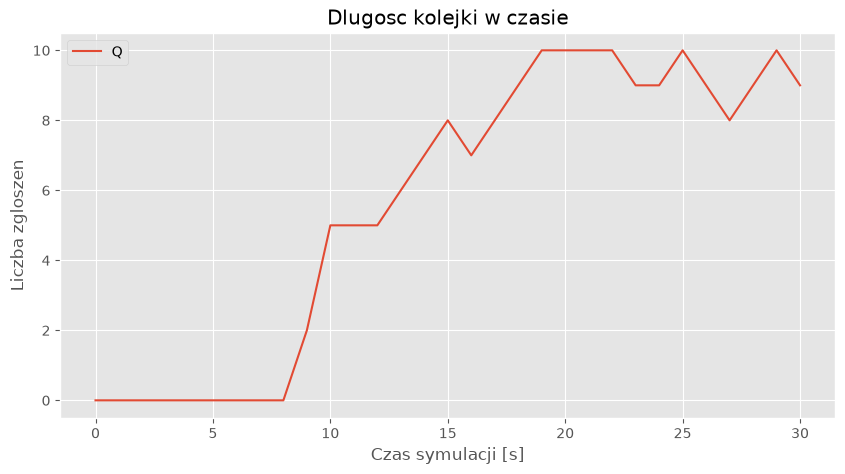

In [14]:
plt.figure(figsize=(10, 5))
plt.plot(czas, dlugosc_kolejki_w_czasie, label="Q")
plt.title("Dlugosc kolejki w czasie")
plt.xlabel("Czas symulacji [s]")
plt.ylabel("Liczba zgloszen")
plt.grid(True)
plt.legend()
plt.show()

### 7.3. Wykres W – średni czas oczekiwania

Wykres przedstawia zmiany średniego czasu oczekiwania zgłoszeń na obsługę w trakcie symulacji.

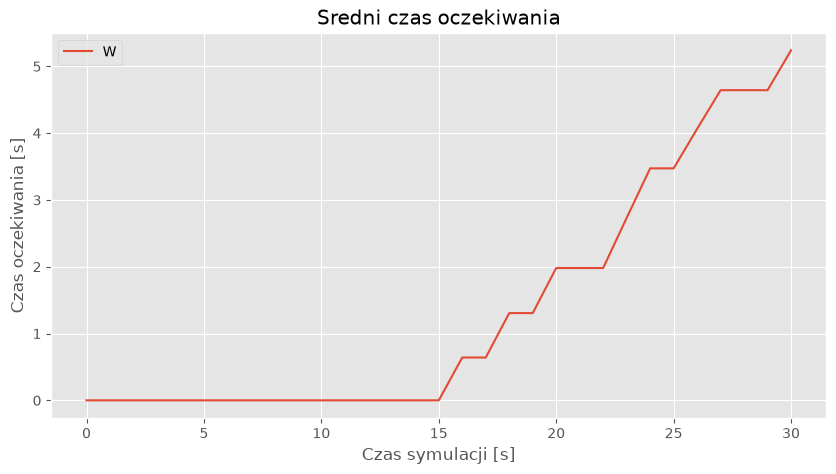

In [15]:
plt.figure(figsize=(10, 5))
plt.plot(czas, oczekiwanie_w_czasie, label="W")
plt.title("Sredni czas oczekiwania")
plt.xlabel("Czas symulacji [s]")
plt.ylabel("Czas oczekiwania [s]")
plt.grid(True)
plt.legend()
plt.show()

### 7.4. Wykres Ro – wykorzystanie kanałów

Wykres przedstawia poziom wykorzystania dostępnych kanałów w kolejnych sekundach symulacji.

Pozwala ocenić obciążenie stacji bazowej i efektywność wykorzystania jej zasobów.

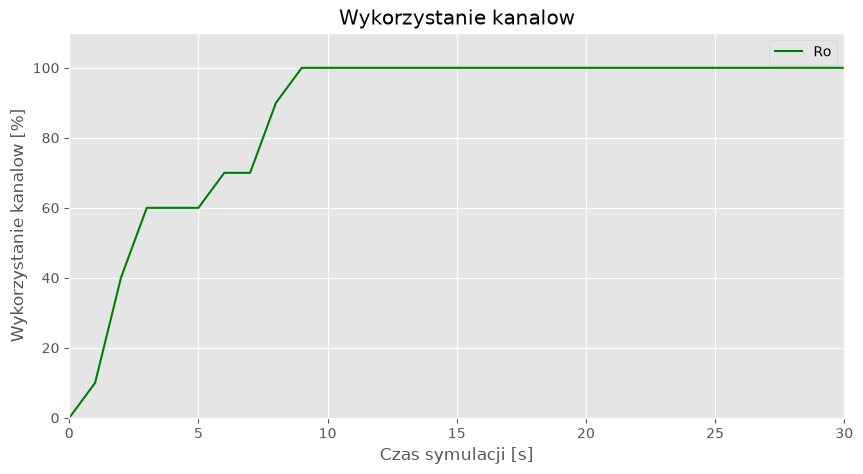

In [18]:
plt.figure(figsize=(10, 5))
plt.plot(czas, wykorzystanie_w_czasie, label="Ro", color="green")
plt.title("Wykorzystanie kanalow")
plt.xlabel("Czas symulacji [s]")
plt.ylabel("Wykorzystanie kanalow [%]")
plt.xlim(0, czas_symulacji)
plt.ylim(0, 110)
plt.grid(True)
plt.legend()
plt.show()

## 8. Zapis wyników symulacji do pliku
Na tym etapie zapisujemy parametry symulacji oraz uzyskane wyniki w pliku CSV. Plik zawiera wartości parametrów symulacji oraz dane dotyczące intensywności ruchu ρ, średniej długości kolejki Q i średniego czasu oczekiwania W.

In [20]:
wyniki_symulacji = pd.DataFrame({
    "Czas": czas,
    "Ro": wykorzystanie_w_czasie,
    "Q": dlugosc_kolejki_w_czasie,
    "W": oczekiwanie_w_czasie
})

parametry = {
    "Liczba kanalow": liczba_kanalow,
    "Lambda": lambda_ruchu,
    "Sredni czas rozmowy": sredni_czas_rozmowy,
    "Odchylenie standardowe": odchylenie_standardowe,
    "Minimalny czas": minimalny_czas,
    "Maksymalny czas": maksymalny_czas,
    "Dlugosc kolejki": dlugosc_kolejki,
    "Czas symulacji": czas_symulacji
}

for nazwa, wartosc in parametry.items():
    wyniki_symulacji[nazwa] = wartosc

wyniki_symulacji.to_csv("wyniki_symulacji.csv", index=False)

print("Parametry i wyniki symulacji zostaly zapisane.")

Parametry i wyniki symulacji zostaly zapisane.


## 9. Sprawdzenie zapisanego pliku
Na tym etapie sprawdzamy poprawność zapisanego pliku CSV. Weryfikujemy, czy plik zawiera wszystkie parametry symulacji oraz wyniki dotyczące intensywności ruchu, średniej długości kolejki i średniego czasu oczekiwania.

Dodatkowo wyświetlamy pierwsze rekordy pliku oraz sprawdzamy liczbę zapisanych wierszy i kolumn.

In [21]:
plik = pd.read_csv("wyniki_symulacji.csv")

print("Zawartosc zapisanego pliku:")
display(plik.head())

print("\nLiczba wierszy:", len(plik))
print("Liczba kolumn:", len(plik.columns))
print("\nNazwy kolumn:")
print(list(plik.columns))

Zawartosc zapisanego pliku:


,Czas,Ro,Q,W,Liczba kanalow,Lambda,Sredni czas rozmowy,Odchylenie standardowe,Minimalny czas,Maksymalny czas,Dlugosc kolejki,Czas symulacji
0,0,0.0,0,0.0,10,1.0,20,5,10,30,10,30
1,1,10.0,0,0.0,10,1.0,20,5,10,30,10,30
2,2,40.0,0,0.0,10,1.0,20,5,10,30,10,30
3,3,60.0,0,0.0,10,1.0,20,5,10,30,10,30
4,4,60.0,0,0.0,10,1.0,20,5,10,30,10,30



Liczba wierszy: 31
Liczba kolumn: 12

Nazwy kolumn:
['Czas', 'Ro', 'Q', 'W', 'Liczba kanalow', 'Lambda', 'Sredni czas rozmowy', 'Odchylenie standardowe', 'Minimalny czas', 'Maksymalny czas', 'Dlugosc kolejki', 'Czas symulacji']


## 10. Wnioski

W ramach laboratorium zaimplementowano symulator stacji bazowej wykorzystujący rozkład Poissona do generowania momentów przybycia zgłoszeń oraz rozkład Gaussa do określania czasu trwania połączeń.

Program umożliwia symulację obsługi zgłoszeń przez określoną liczbę kanałów, analizę długości kolejki oraz czasu oczekiwania na obsługę.

Na podstawie przeprowadzonej symulacji wygenerowano wykresy przedstawiające intensywność ruchu, średnią długość kolejki oraz średni czas oczekiwania.

Wyniki symulacji wraz z parametrami zostały zapisane w pliku CSV.

Zrealizowany program pozwala analizować działanie stacji bazowej i oceniać obciążenie systemu w zależności od przyjętych parametrów.